# DATA 266 Homework 9 - Conditional Latent Diffusion on Fashion-MNIST

**Student:** Nikhil Kanaparthi  
**SID4:** 6441  
**Seed:** 6441


## 1. Install dependencies

Run this cell once per new Colab runtime. A runtime restart is normally not required.


In [1]:
!pip -q install -U diffusers transformers accelerate safetensors pandas tabulate
print("STEP 1: PASS")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
STEP 1: PASS


## 2. Imports, reproducibility, and assignment configuration

Fashion-MNIST images are resized to **128x128** before VAE encoding. The Stable
Diffusion VAE downsamples by a factor of 8, producing **4x16x16 latents**. This
choice is deliberate: the assignment requires self-attention at 16x16.


In [2]:
from __future__ import annotations

import hashlib
import json
import math
import os
import platform
import random
import shutil
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torchvision.utils import make_grid

import diffusers
from diffusers import AutoencoderKL
import transformers
import accelerate
import safetensors
from safetensors.torch import save_file


# ---------------------------
# Student and Step 0 settings
# ---------------------------
STUDENT = "Nikhil Kanaparthi"
SID4 = 6441
SEED = 6441
SLICE = SID4 % 1000
HP_ID = SID4 % 6 + 1

# ---------------------------
# Required assignment settings
# ---------------------------
VAE_MODEL = "stabilityai/sd-vae-ft-mse"
DATASET_NAME = "FashionMNIST"
IMAGE_SIZE = 128                 # 128 / 8 = 16 latent spatial size
LATENT_CHANNELS = 4
LATENT_SCALE = 0.18215
NUM_DIFFUSION_STEPS = 1000
BETA_START = 1e-4
BETA_END = 0.02
BASE_CHANNELS = 64
CHANNEL_MULTIPLIERS = (1, 2, 4)
NUM_CLASSES = 10
NULL_LABEL = 10
LABEL_DROP_PROBABILITY = 0.10
NUM_EPOCHS = 50
LEARNING_RATE = 2e-5
TRAIN_BATCH_SIZE = 128
EVAL_BATCH_SIZE = 128
VAE_BATCH_SIZE = 64
GUIDANCE_SCALE = 3.0
NUM_SAMPLES = 64

# Leave False for the submitted run. True is only for a quick code check.
FAST_DEBUG = False
if FAST_DEBUG:
    NUM_EPOCHS = 2
    TRAIN_SAMPLE_LIMIT = 2048
    TEST_SAMPLE_LIMIT = 512
else:
    TRAIN_SAMPLE_LIMIT = None
    TEST_SAMPLE_LIMIT = None

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
VAE_DTYPE = torch.float16 if USE_AMP else torch.float32
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0

OUTPUT_DIR = Path("/content/HW9_outputs") if Path("/content").exists() else Path.cwd() / "HW9_outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
CHECKPOINT_DIR = Path("/content/HW9_checkpoints") if Path("/content").exists() else Path.cwd() / "HW9_checkpoints"
for directory in (OUTPUT_DIR, FIGURE_DIR, MODEL_DIR, CHECKPOINT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

RUN_LOG_LINES = []

def log(message: str) -> None:
    line = f"{datetime.now(timezone.utc).isoformat()} | {message}"
    RUN_LOG_LINES.append(line)
    print(line)

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
gpu_memory_gib = (
    torch.cuda.get_device_properties(0).total_memory / 1024**3
    if torch.cuda.is_available() else 0.0
)

log(f"Student={STUDENT}; SID4={SID4}; SEED={SEED}; SLICE={SLICE}; HP_ID={HP_ID}")
log(f"Device={DEVICE}; GPU={gpu_name}; GPU memory={gpu_memory_gib:.2f} GiB")
log(f"Output directory={OUTPUT_DIR}")

assert NUM_DIFFUSION_STEPS == 1000
assert NUM_EPOCHS == 50 or FAST_DEBUG
assert LEARNING_RATE == 2e-5
assert LABEL_DROP_PROBABILITY == 0.1
assert GUIDANCE_SCALE == 3.0
assert IMAGE_SIZE // 8 == 16

print("STEP 2: PASS")


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


2026-11-03T23:20:07.912686+00:00 | Student=Nikhil Kanaparthi; SID4=6441; SEED=6441; SLICE=441; HP_ID=4
2026-11-03T23:20:07.912890+00:00 | Device=cuda; GPU=Tesla T4; GPU memory=14.56 GiB
2026-11-03T23:20:07.912971+00:00 | Output directory=/content/HW9_outputs
STEP 2: PASS


## 3. Load Fashion-MNIST

The grayscale channel is replicated to three channels because the Stable
Diffusion VAE expects RGB input. Pixel values are normalized to `[-1, 1]`.
The training set is used to fit the denoiser; the official test split is used
only for reconstruction checks and held-out noise-prediction loss.


In [3]:
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BICUBIC, antialias=True),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

DATA_ROOT = Path("/content/data") if Path("/content").exists() else Path.cwd() / "data"
train_dataset_full = datasets.FashionMNIST(DATA_ROOT, train=True, download=True, transform=transform)
test_dataset_full = datasets.FashionMNIST(DATA_ROOT, train=False, download=True, transform=transform)
class_names = train_dataset_full.classes

if TRAIN_SAMPLE_LIMIT is not None:
    rng = np.random.default_rng(SEED)
    train_indices = rng.choice(len(train_dataset_full), TRAIN_SAMPLE_LIMIT, replace=False)
    test_indices = rng.choice(len(test_dataset_full), TEST_SAMPLE_LIMIT, replace=False)
    train_dataset = Subset(train_dataset_full, train_indices.tolist())
    test_dataset = Subset(test_dataset_full, test_indices.tolist())
else:
    train_dataset = train_dataset_full
    test_dataset = test_dataset_full

train_encode_loader = DataLoader(
    train_dataset, batch_size=VAE_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP,
)
test_encode_loader = DataLoader(
    test_dataset, batch_size=VAE_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP,
)

sample_image, sample_label = train_dataset[0]
print("Training examples:", len(train_dataset))
print("Test examples:", len(test_dataset))
print("Image tensor shape:", tuple(sample_image.shape))
print("Classes:", dict(enumerate(class_names)))

assert sample_image.shape == (3, IMAGE_SIZE, IMAGE_SIZE)
assert len(class_names) == NUM_CLASSES
print("STEP 3: PASS")


100%|██████████| 26.4M/26.4M [00:02<00:00, 9.90MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 168kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.12MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.0MB/s]


Training examples: 60000
Test examples: 10000
Image tensor shape: (3, 128, 128)
Classes: {0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'}
STEP 3: PASS


## 4. Load the pretrained VAE and measure reconstruction MSE

The VAE is frozen. Encoding uses the posterior mean for a deterministic
reconstruction measurement and multiplies the latent by the required scaling
factor `0.18215`. Decoding divides by the same factor.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


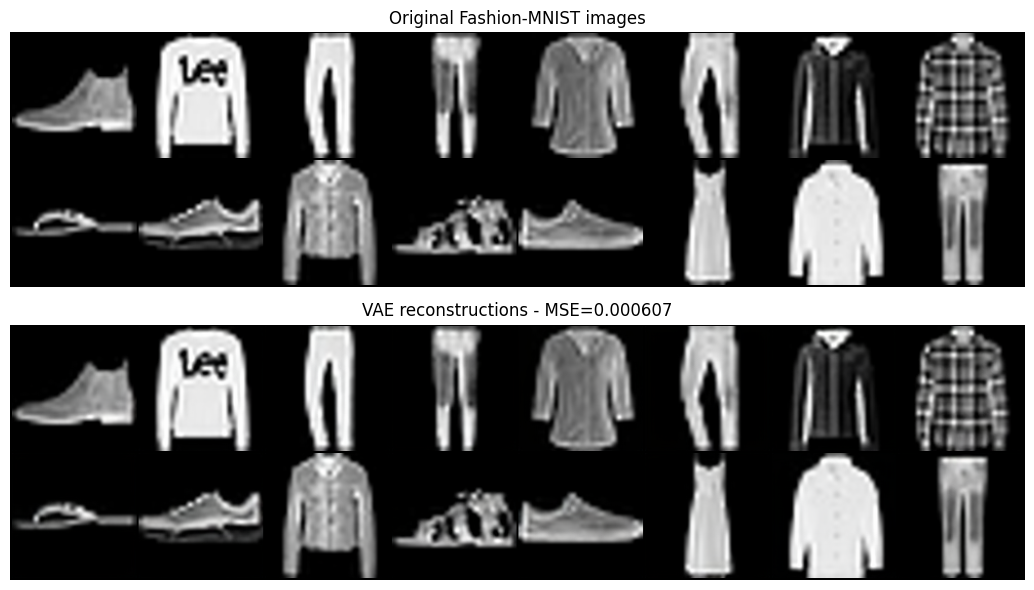

Latent shape: (16, 4, 16, 16)
Reconstruction MSE: 0.000607
2026-11-03T23:20:39.434410+00:00 | VAE reconstruction MSE=0.00060739
STEP 4: PASS


In [4]:
vae = AutoencoderKL.from_pretrained(VAE_MODEL)
vae.requires_grad_(False)
vae.eval().to(DEVICE, dtype=VAE_DTYPE)

def encode_images(images: torch.Tensor) -> torch.Tensor:
    images = images.to(DEVICE, dtype=VAE_DTYPE, non_blocking=True)
    posterior = vae.encode(images).latent_dist
    return posterior.mean * LATENT_SCALE

def decode_latents(latents: torch.Tensor, batch_size: int = 16) -> torch.Tensor:
    decoded_batches = []
    with torch.inference_mode():
        for start in range(0, len(latents), batch_size):
            z = latents[start:start + batch_size].to(DEVICE, dtype=VAE_DTYPE)
            decoded = vae.decode(z / LATENT_SCALE).sample.float().cpu()
            decoded_batches.append(decoded)
    return torch.cat(decoded_batches, dim=0).clamp(-1, 1)

recon_images, recon_labels = next(iter(test_encode_loader))
recon_images = recon_images[:16]
recon_labels = recon_labels[:16]
with torch.inference_mode():
    recon_latents = encode_images(recon_images)
    reconstructions = decode_latents(recon_latents)

reconstruction_mse = F.mse_loss(reconstructions, recon_images.float()).item()

original_grid = make_grid((recon_images + 1) / 2, nrow=8, padding=2)
reconstruction_grid = make_grid((reconstructions + 1) / 2, nrow=8, padding=2)

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].imshow(original_grid.permute(1, 2, 0).numpy())
axes[0].set_title("Original Fashion-MNIST images")
axes[1].imshow(reconstruction_grid.permute(1, 2, 0).numpy())
axes[1].set_title(f"VAE reconstructions - MSE={reconstruction_mse:.6f}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "vae_reconstruction.png", dpi=180, bbox_inches="tight")
plt.show()

reconstruction_record = {
    "model": VAE_MODEL,
    "latent_scale": LATENT_SCALE,
    "input_shape": list(recon_images.shape),
    "latent_shape": list(recon_latents.shape),
    "mse_on_normalized_pixels": reconstruction_mse,
}
(OUTPUT_DIR / "reconstruction_metrics.json").write_text(
    json.dumps(reconstruction_record, indent=2), encoding="utf-8"
)

print("Latent shape:", tuple(recon_latents.shape))
print(f"Reconstruction MSE: {reconstruction_mse:.6f}")
assert recon_latents.shape[1:] == (LATENT_CHANNELS, 16, 16)
log(f"VAE reconstruction MSE={reconstruction_mse:.8f}")
print("STEP 4: PASS")


## 5. Precompute scaled VAE latents

The frozen VAE does not need to run during every diffusion epoch. We encode
each image once, retain the scaled latent in CPU memory, and train the U-Net on
those cached latents. This preserves the required experiment while making 50
epochs practical on a Colab GPU.


In [5]:
def cache_latents(loader: DataLoader, description: str):
    latent_batches, label_batches = [], []
    with torch.inference_mode():
        for images, labels in tqdm(loader, desc=description):
            latents = encode_images(images)
            latent_batches.append(latents.cpu().to(torch.float16))
            label_batches.append(labels.cpu().to(torch.long))
    return torch.cat(latent_batches), torch.cat(label_batches)

cache_start = time.perf_counter()
train_latents, train_labels = cache_latents(train_encode_loader, "Encoding training images")
test_latents, test_labels = cache_latents(test_encode_loader, "Encoding test images")
cache_seconds = time.perf_counter() - cache_start

latent_train_dataset = TensorDataset(train_latents, train_labels)
latent_test_dataset = TensorDataset(test_latents, test_labels)

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    latent_train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=NUM_WORKERS,
    pin_memory=USE_AMP,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    latent_test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=USE_AMP,
    persistent_workers=NUM_WORKERS > 0,
)

print("Cached training latents:", tuple(train_latents.shape), train_latents.dtype)
print("Cached test latents:", tuple(test_latents.shape), test_latents.dtype)
print(f"Encoding time: {cache_seconds:.2f} seconds")
assert train_latents.shape[1:] == (4, 16, 16)
assert train_latents.isfinite().all()
log(f"Cached {len(train_latents)} train and {len(test_latents)} test latents in {cache_seconds:.2f}s")
print("STEP 5: PASS")


Encoding training images:   0%|          | 0/938 [00:00<?, ?it/s]

Encoding test images:   0%|          | 0/157 [00:00<?, ?it/s]

Cached training latents: (60000, 4, 16, 16) torch.float16
Cached test latents: (10000, 4, 16, 16) torch.float16
Encoding time: 463.72 seconds
2026-11-03T23:28:23.694188+00:00 | Cached 60000 train and 10000 test latents in 463.72s
STEP 5: PASS


## 6. Forward Gaussian diffusion in latent space

The schedule has (T=1000), β₁=`1e-4`, and βₜ=`0.02`. For a clean scaled latent
(z_0), the direct sampling equation is

\[
z_t = \sqrt{\bar{\alpha}_t}z_0 + \sqrt{1-\bar{\alpha}_t}\epsilon,
\qquad \epsilon\sim\mathcal{N}(0,I).
\]

The required assignment timesteps `{0, 200, 500, 800, 1000}` are displayed.
Because Python indices are zero-based, assignment timestep 1000 maps to schedule
index 999; timestep 0 is the clean latent.


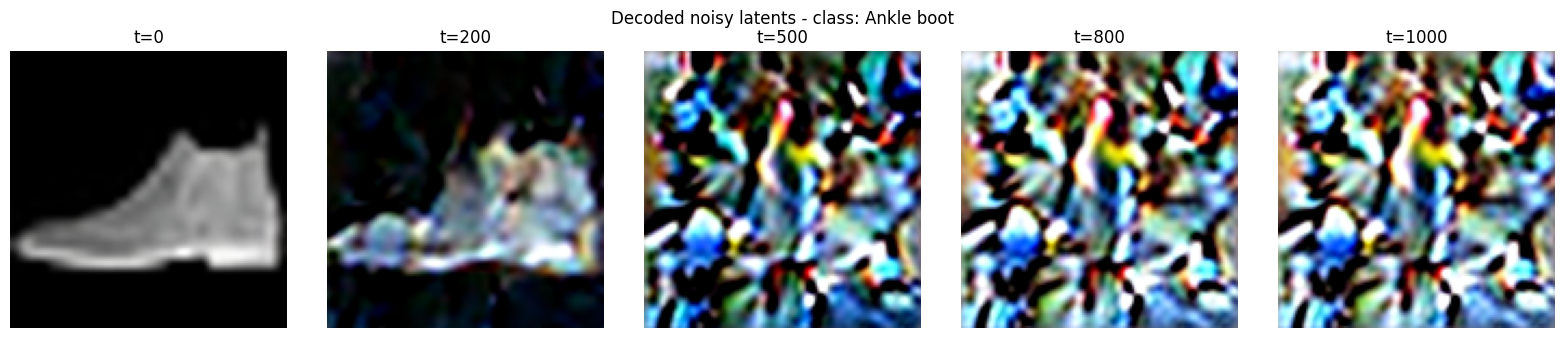

STEP 6: PASS


In [6]:
betas = torch.linspace(BETA_START, BETA_END, NUM_DIFFUSION_STEPS, device=DEVICE, dtype=torch.float32)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_prev = F.pad(alpha_bars[:-1], (1, 0), value=1.0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

def extract(schedule: torch.Tensor, t: torch.Tensor, x_shape: tuple[int, ...]) -> torch.Tensor:
    values = schedule.gather(0, t)
    return values.reshape(t.shape[0], *((1,) * (len(x_shape) - 1)))

def q_sample(z0: torch.Tensor, t: torch.Tensor, noise: torch.Tensor | None = None):
    if noise is None:
        noise = torch.randn_like(z0)
    zt = (
        extract(sqrt_alpha_bars, t, z0.shape) * z0
        + extract(sqrt_one_minus_alpha_bars, t, z0.shape) * noise
    )
    return zt, noise

clean_latent = test_latents[0:1].to(DEVICE, dtype=torch.float32)
fixed_noise = torch.randn(clean_latent.shape, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(SEED))
assignment_timesteps = [0, 200, 500, 800, 1000]
noisy_latents = []

for assignment_t in assignment_timesteps:
    if assignment_t == 0:
        zt = clean_latent
    else:
        schedule_index = torch.tensor([assignment_t - 1], device=DEVICE, dtype=torch.long)
        zt, _ = q_sample(clean_latent, schedule_index, fixed_noise)
    noisy_latents.append(zt.cpu())

decoded_noisy = decode_latents(torch.cat(noisy_latents, dim=0))
fig, axes = plt.subplots(1, len(assignment_timesteps), figsize=(16, 3.4))
for ax, image, timestep in zip(axes, decoded_noisy, assignment_timesteps):
    ax.imshow(((image + 1) / 2).permute(1, 2, 0).numpy())
    ax.set_title(f"t={timestep}")
    ax.axis("off")
plt.suptitle(f"Decoded noisy latents - class: {class_names[int(test_labels[0])]}")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "forward_diffusion_decodes.png", dpi=180, bbox_inches="tight")
plt.show()

assert betas.shape == (1000,)
assert torch.all(betas[1:] >= betas[:-1])
print("STEP 6: PASS")


## 7. Conditional latent U-Net

Architecture checklist:

- Input: scaled VAE latent `(4, 16, 16)`
- Base channels: 64; multipliers: `(1, 2, 4)`
- Sinusoidal timestep embedding followed by an MLP
- Eleven label embeddings: classes 0-9 plus null label 10
- Residual blocks with GroupNorm and SiLU
- Spatial self-attention and conditioning cross-attention at 16x16
- Self-attention and cross-attention in the bottleneck
- Two downsampling and two upsampling operations with skip connections


In [7]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, timesteps: torch.Tensor) -> torch.Tensor:
        half = self.dim // 2
        frequency = torch.exp(
            -math.log(10000) * torch.arange(half, device=timesteps.device) / (half - 1)
        )
        angles = timesteps.float()[:, None] * frequency[None, :]
        return torch.cat([angles.sin(), angles.cos()], dim=-1)


class ResidualBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, embedding_dim: int):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.embedding_projection = nn.Linear(embedding_dim, out_channels)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = nn.Conv2d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x: torch.Tensor, embedding: torch.Tensor) -> torch.Tensor:
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.embedding_projection(F.silu(embedding))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class SpatialSelfAttention(nn.Module):
    def __init__(self, channels: int, num_heads: int = 4):
        super().__init__()
        assert channels % num_heads == 0
        self.channels = channels
        self.num_heads = num_heads
        self.head_dim = channels // num_heads
        self.norm = nn.GroupNorm(8, channels)
        self.qkv = nn.Conv2d(channels, 3 * channels, 1)
        self.projection = nn.Conv2d(channels, channels, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        batch, channels, height, width = x.shape
        qkv = self.qkv(self.norm(x)).reshape(
            batch, 3, self.num_heads, self.head_dim, height * width
        )
        q, k, v = qkv.unbind(dim=1)
        q, k, v = q.transpose(-2, -1), k.transpose(-2, -1), v.transpose(-2, -1)
        attended = F.scaled_dot_product_attention(q, k, v)
        attended = attended.transpose(-2, -1).reshape(batch, channels, height, width)
        return x + self.projection(attended)


class SpatialCrossAttention(nn.Module):
    # Cross-attend spatial tokens to two tokens derived from label+time conditioning.
    def __init__(self, channels: int, embedding_dim: int, num_heads: int = 4):
        super().__init__()
        self.norm = nn.GroupNorm(8, channels)
        self.context_projection = nn.Linear(embedding_dim, 2 * channels)
        self.attention = nn.MultiheadAttention(channels, num_heads, batch_first=True)
        self.output_projection = nn.Linear(channels, channels)

    def forward(self, x: torch.Tensor, embedding: torch.Tensor) -> torch.Tensor:
        batch, channels, height, width = x.shape
        residual = x.flatten(2).transpose(1, 2)
        query = self.norm(x).flatten(2).transpose(1, 2)
        context = self.context_projection(embedding).reshape(batch, 2, channels)
        attended, _ = self.attention(query, context, context, need_weights=False)
        output = residual + self.output_projection(attended)
        return output.transpose(1, 2).reshape(batch, channels, height, width)


class AttentionBlock(nn.Module):
    def __init__(self, channels: int, embedding_dim: int):
        super().__init__()
        self.self_attention = SpatialSelfAttention(channels)
        self.cross_attention = SpatialCrossAttention(channels, embedding_dim)

    def forward(self, x: torch.Tensor, embedding: torch.Tensor) -> torch.Tensor:
        return self.cross_attention(self.self_attention(x), embedding)


class DownBlock(nn.Module):
    def __init__(self, in_channels, out_channels, embedding_dim, use_attention, downsample):
        super().__init__()
        self.res1 = ResidualBlock(in_channels, out_channels, embedding_dim)
        self.res2 = ResidualBlock(out_channels, out_channels, embedding_dim)
        self.attention = AttentionBlock(out_channels, embedding_dim) if use_attention else None
        self.downsample = (
            nn.Conv2d(out_channels, out_channels, 4, stride=2, padding=1)
            if downsample else nn.Identity()
        )

    def forward(self, x, embedding):
        x = self.res1(x, embedding)
        x = self.res2(x, embedding)
        if self.attention is not None:
            x = self.attention(x, embedding)
        return x, self.downsample(x)


class UpBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels, embedding_dim, use_attention, next_channels=None):
        super().__init__()
        self.res1 = ResidualBlock(in_channels + skip_channels, out_channels, embedding_dim)
        self.res2 = ResidualBlock(out_channels, out_channels, embedding_dim)
        self.attention = AttentionBlock(out_channels, embedding_dim) if use_attention else None
        self.upsample = (
            nn.ConvTranspose2d(out_channels, next_channels, 4, stride=2, padding=1)
            if next_channels is not None else nn.Identity()
        )

    def forward(self, x, skip, embedding):
        if x.shape[-2:] != skip.shape[-2:]:
            raise ValueError(f"Skip mismatch: x={x.shape}, skip={skip.shape}")
        x = torch.cat([x, skip], dim=1)
        x = self.res1(x, embedding)
        x = self.res2(x, embedding)
        if self.attention is not None:
            x = self.attention(x, embedding)
        return self.upsample(x)


class ConditionalLatentUNet(nn.Module):
    def __init__(self, latent_channels=4, base_channels=64, num_classes=10):
        super().__init__()
        embedding_dim = base_channels * 4
        self.null_label = num_classes

        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(base_channels),
            nn.Linear(base_channels, embedding_dim),
            nn.SiLU(),
            nn.Linear(embedding_dim, embedding_dim),
        )
        self.label_embedding = nn.Embedding(num_classes + 1, embedding_dim)

        self.input_conv = nn.Conv2d(latent_channels, base_channels, 3, padding=1)
        self.down1 = DownBlock(base_channels, 64, embedding_dim, use_attention=True, downsample=True)
        self.down2 = DownBlock(64, 128, embedding_dim, use_attention=False, downsample=True)
        self.down3 = DownBlock(128, 256, embedding_dim, use_attention=False, downsample=False)

        self.mid1 = ResidualBlock(256, 256, embedding_dim)
        self.mid_attention = AttentionBlock(256, embedding_dim)
        self.mid2 = ResidualBlock(256, 256, embedding_dim)

        self.up3 = UpBlock(256, 256, 256, embedding_dim, use_attention=False, next_channels=128)
        self.up2 = UpBlock(128, 128, 128, embedding_dim, use_attention=False, next_channels=64)
        self.up1 = UpBlock(64, 64, 64, embedding_dim, use_attention=True, next_channels=None)

        self.output_norm = nn.GroupNorm(8, 64)
        self.output_conv = nn.Conv2d(64, latent_channels, 3, padding=1)

    def forward(self, x: torch.Tensor, timesteps: torch.Tensor, labels: torch.Tensor | None = None):
        if labels is None:
            labels = torch.full(
                (x.shape[0],), self.null_label, device=x.device, dtype=torch.long
            )
        time_embedding = self.time_mlp(timesteps)
        conditioning = time_embedding + self.label_embedding(labels)

        x = self.input_conv(x)
        skip1, x = self.down1(x, conditioning)   # 16x16 -> 8x8
        skip2, x = self.down2(x, conditioning)   # 8x8 -> 4x4
        skip3, x = self.down3(x, conditioning)   # 4x4

        x = self.mid1(x, conditioning)
        x = self.mid_attention(x, conditioning)
        x = self.mid2(x, conditioning)

        x = self.up3(x, skip3, conditioning)     # 4x4 -> 8x8
        x = self.up2(x, skip2, conditioning)     # 8x8 -> 16x16
        x = self.up1(x, skip1, conditioning)     # 16x16
        return self.output_conv(F.silu(self.output_norm(x)))


model = ConditionalLatentUNet(
    latent_channels=LATENT_CHANNELS,
    base_channels=BASE_CHANNELS,
    num_classes=NUM_CLASSES,
).to(DEVICE)

total_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

with torch.inference_mode():
    shape_test_x = torch.randn(2, 4, 16, 16, device=DEVICE)
    shape_test_t = torch.tensor([0, 999], device=DEVICE)
    shape_test_y = torch.tensor([0, NULL_LABEL], device=DEVICE)
    shape_test_output = model(shape_test_x, shape_test_t, shape_test_y)

print(model)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print("Shape test:", tuple(shape_test_x.shape), "->", tuple(shape_test_output.shape))
assert shape_test_output.shape == shape_test_x.shape
log(f"Created ConditionalLatentUNet with {total_parameters:,} parameters")
print("STEP 7: PASS")


ConditionalLatentUNet(
  (time_mlp): Sequential(
    (0): SinusoidalTimeEmbedding()
    (1): Linear(in_features=64, out_features=256, bias=True)
    (2): SiLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
  (label_embedding): Embedding(11, 256)
  (input_conv): Conv2d(4, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down1): DownBlock(
    (res1): ResidualBlock(
      (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (embedding_projection): Linear(in_features=256, out_features=64, bias=True)
      (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (skip): Identity()
    )
    (res2): ResidualBlock(
      (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (embedding_projection): Linear(in_features=256

## 8. Train for 50 epochs

The model predicts the Gaussian noise added to each clean latent. Label dropout
is applied independently to each example with probability 0.1 by replacing its
class label with the null label. The held-out test split is used to report a
conditional noise-prediction MSE after every epoch.

Checkpoints are written outside the final submission directory so optimizer
states do not make the submission ZIP unnecessarily large. Re-running this cell
resumes automatically from the latest checkpoint if one exists.


In [8]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
checkpoint_path = CHECKPOINT_DIR / "latest_checkpoint.pt"
history = []
start_epoch = 0

if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    if checkpoint.get("scaler") is not None and USE_AMP:
        scaler.load_state_dict(checkpoint["scaler"])
    history = checkpoint.get("history", [])
    start_epoch = int(checkpoint["epoch"])
    log(f"Resuming training from completed epoch {start_epoch}")
else:
    log("Starting diffusion training from epoch 1")

training_start = time.perf_counter()

for epoch in range(start_epoch, NUM_EPOCHS):
    model.train()
    train_loss_sum = 0.0
    train_example_count = 0
    dropped_label_count = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} - train", leave=False)
    for clean_latents, labels in progress:
        clean_latents = clean_latents.to(DEVICE, dtype=torch.float32, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        batch_size = clean_latents.shape[0]

        timesteps = torch.randint(0, NUM_DIFFUSION_STEPS, (batch_size,), device=DEVICE)
        noise = torch.randn_like(clean_latents)
        noisy_latents, noise_target = q_sample(clean_latents, timesteps, noise)

        cfg_labels = labels.clone()
        drop_mask = torch.rand(batch_size, device=DEVICE) < LABEL_DROP_PROBABILITY
        cfg_labels[drop_mask] = NULL_LABEL
        dropped_label_count += int(drop_mask.sum())

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            noise_prediction = model(noisy_latents, timesteps, cfg_labels)
            loss = F.mse_loss(noise_prediction.float(), noise_target.float())

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_sum += loss.item() * batch_size
        train_example_count += batch_size
        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = train_loss_sum / train_example_count

    model.eval()
    validation_loss_sum = 0.0
    validation_example_count = 0
    with torch.inference_mode():
        for clean_latents, labels in tqdm(
            test_loader, desc=f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} - validation", leave=False
        ):
            clean_latents = clean_latents.to(DEVICE, dtype=torch.float32, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            batch_size = clean_latents.shape[0]
            timesteps = torch.randint(0, NUM_DIFFUSION_STEPS, (batch_size,), device=DEVICE)
            noise = torch.randn_like(clean_latents)
            noisy_latents, noise_target = q_sample(clean_latents, timesteps, noise)

            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                noise_prediction = model(noisy_latents, timesteps, labels)
                validation_loss = F.mse_loss(noise_prediction.float(), noise_target.float())

            validation_loss_sum += validation_loss.item() * batch_size
            validation_example_count += batch_size

    validation_loss = validation_loss_sum / validation_example_count
    observed_drop_fraction = dropped_label_count / train_example_count
    epoch_record = {
        "epoch": epoch + 1,
        "train_noise_mse": train_loss,
        "validation_noise_mse": validation_loss,
        "observed_label_drop_fraction": observed_drop_fraction,
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history.append(epoch_record)
    print(
        f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | train={train_loss:.6f} | "
        f"validation={validation_loss:.6f} | label_drop={observed_drop_fraction:.3f}"
    )

    pd.DataFrame(history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
    torch.save(
        {
            "epoch": epoch + 1,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict() if USE_AMP else None,
            "history": history,
        },
        checkpoint_path,
    )

training_seconds_this_session = time.perf_counter() - training_start
total_completed_epochs = len(history)
assert total_completed_epochs == NUM_EPOCHS
log(
    f"Completed {total_completed_epochs} epochs; final train MSE={history[-1]['train_noise_mse']:.8f}; "
    f"final validation MSE={history[-1]['validation_noise_mse']:.8f}; "
    f"this-session training seconds={training_seconds_this_session:.2f}"
)
print("STEP 8: PASS")


2026-11-03T23:28:46.520068+00:00 | Starting diffusion training from epoch 1


/tmp/ipykernel_785/930887467.py:2: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


Epoch 01/50 - train:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 01/50 - validation:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 01/50 | train=0.422170 | validation=0.232717 | label_drop=0.100


Epoch 02/50 - train:   0%|          | 0/469 [00:00<?, ?it/s]

... (142 outputs left out)

Epoch 49/50 | train=0.101275 | validation=0.100539 | label_drop=0.100


Epoch 50/50 - train:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 50/50 - validation:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 50/50 | train=0.100479 | validation=0.102192 | label_drop=0.100
2026-11-04T00:09:55.032219+00:00 | Completed 50 epochs; final train MSE=0.10047932; final validation MSE=0.10219185; this-session training seconds=2468.51
STEP 8: PASS


## 9. Plot the training history and save final model weights


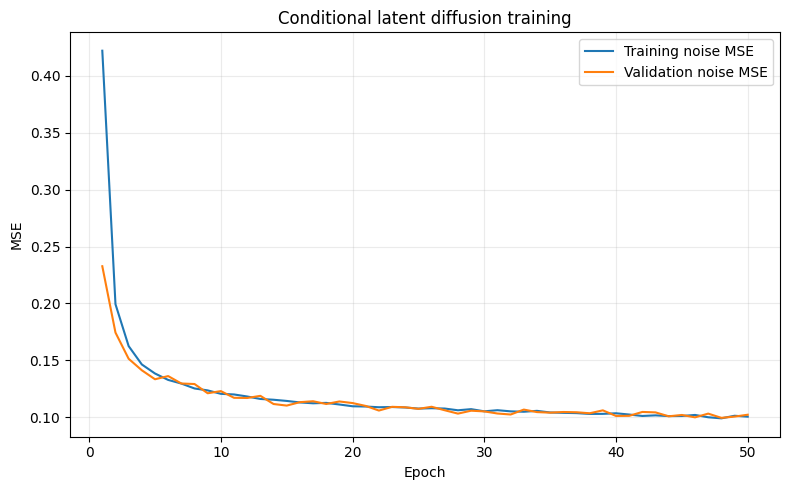

Best validation MSE: 0.099434 at epoch 48
Saved diffusion model: /content/HW9_outputs/models/conditional_latent_unet_fp16.safetensors (22.37 MiB)
STEP 9: PASS


In [9]:
history_df = pd.DataFrame(history)
best_validation_row = history_df.loc[history_df["validation_noise_mse"].idxmin()]

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_noise_mse"], label="Training noise MSE")
plt.plot(history_df["epoch"], history_df["validation_noise_mse"], label="Validation noise MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Conditional latent diffusion training")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "training_loss.png", dpi=180, bbox_inches="tight")
plt.show()

half_precision_state = {
    name: tensor.detach().cpu().to(torch.float16).contiguous()
    if tensor.is_floating_point() else tensor.detach().cpu().contiguous()
    for name, tensor in model.state_dict().items()
}
model_path = MODEL_DIR / "conditional_latent_unet_fp16.safetensors"
save_file(half_precision_state, str(model_path))
model_size_mib = model_path.stat().st_size / 1024**2

(MODEL_DIR / "vae_reference.json").write_text(
    json.dumps({
        "pretrained_model": VAE_MODEL,
        "latent_scaling_factor": LATENT_SCALE,
        "frozen": True,
        "weights_not_duplicated": True,
    }, indent=2),
    encoding="utf-8",
)

print(f"Best validation MSE: {best_validation_row['validation_noise_mse']:.6f} at epoch {int(best_validation_row['epoch'])}")
print(f"Saved diffusion model: {model_path} ({model_size_mib:.2f} MiB)")
print("STEP 9: PASS")


## 10. DDPM sampling with classifier-free guidance

For each reverse-diffusion step, the model predicts noise twice in one combined
batch: once with class labels and once with the null label. The predictions are
combined exactly as required:

\[
\epsilon=(1+w)\epsilon_{cond}-w\epsilon_{uncond},\qquad w=3.
\]

The 64 target labels are `0,1,...,9,0,1,...` until 64 labels are produced.


CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

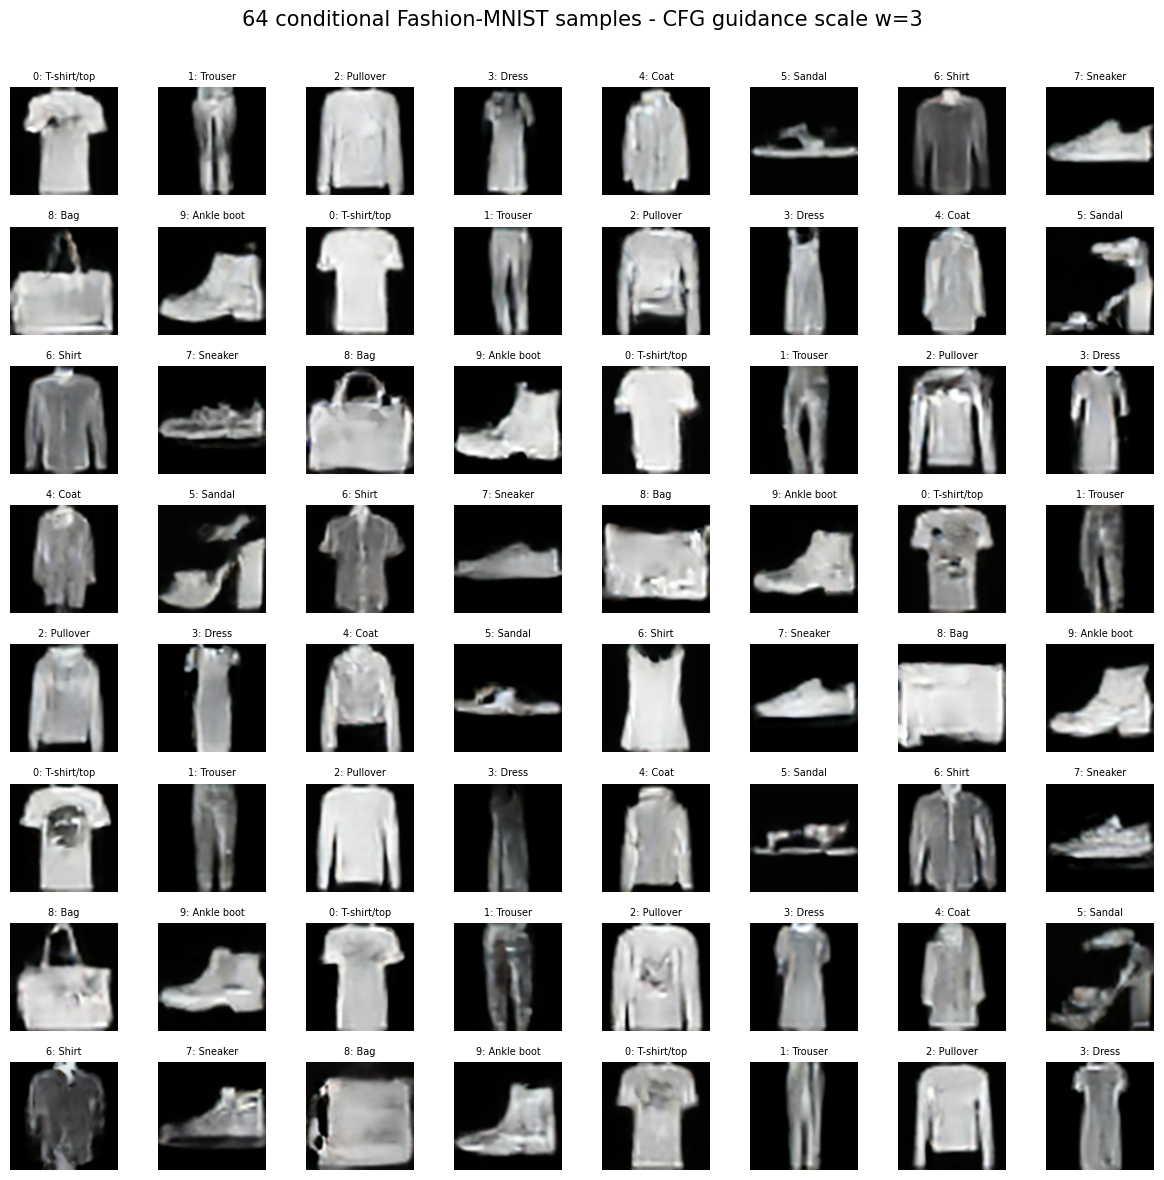

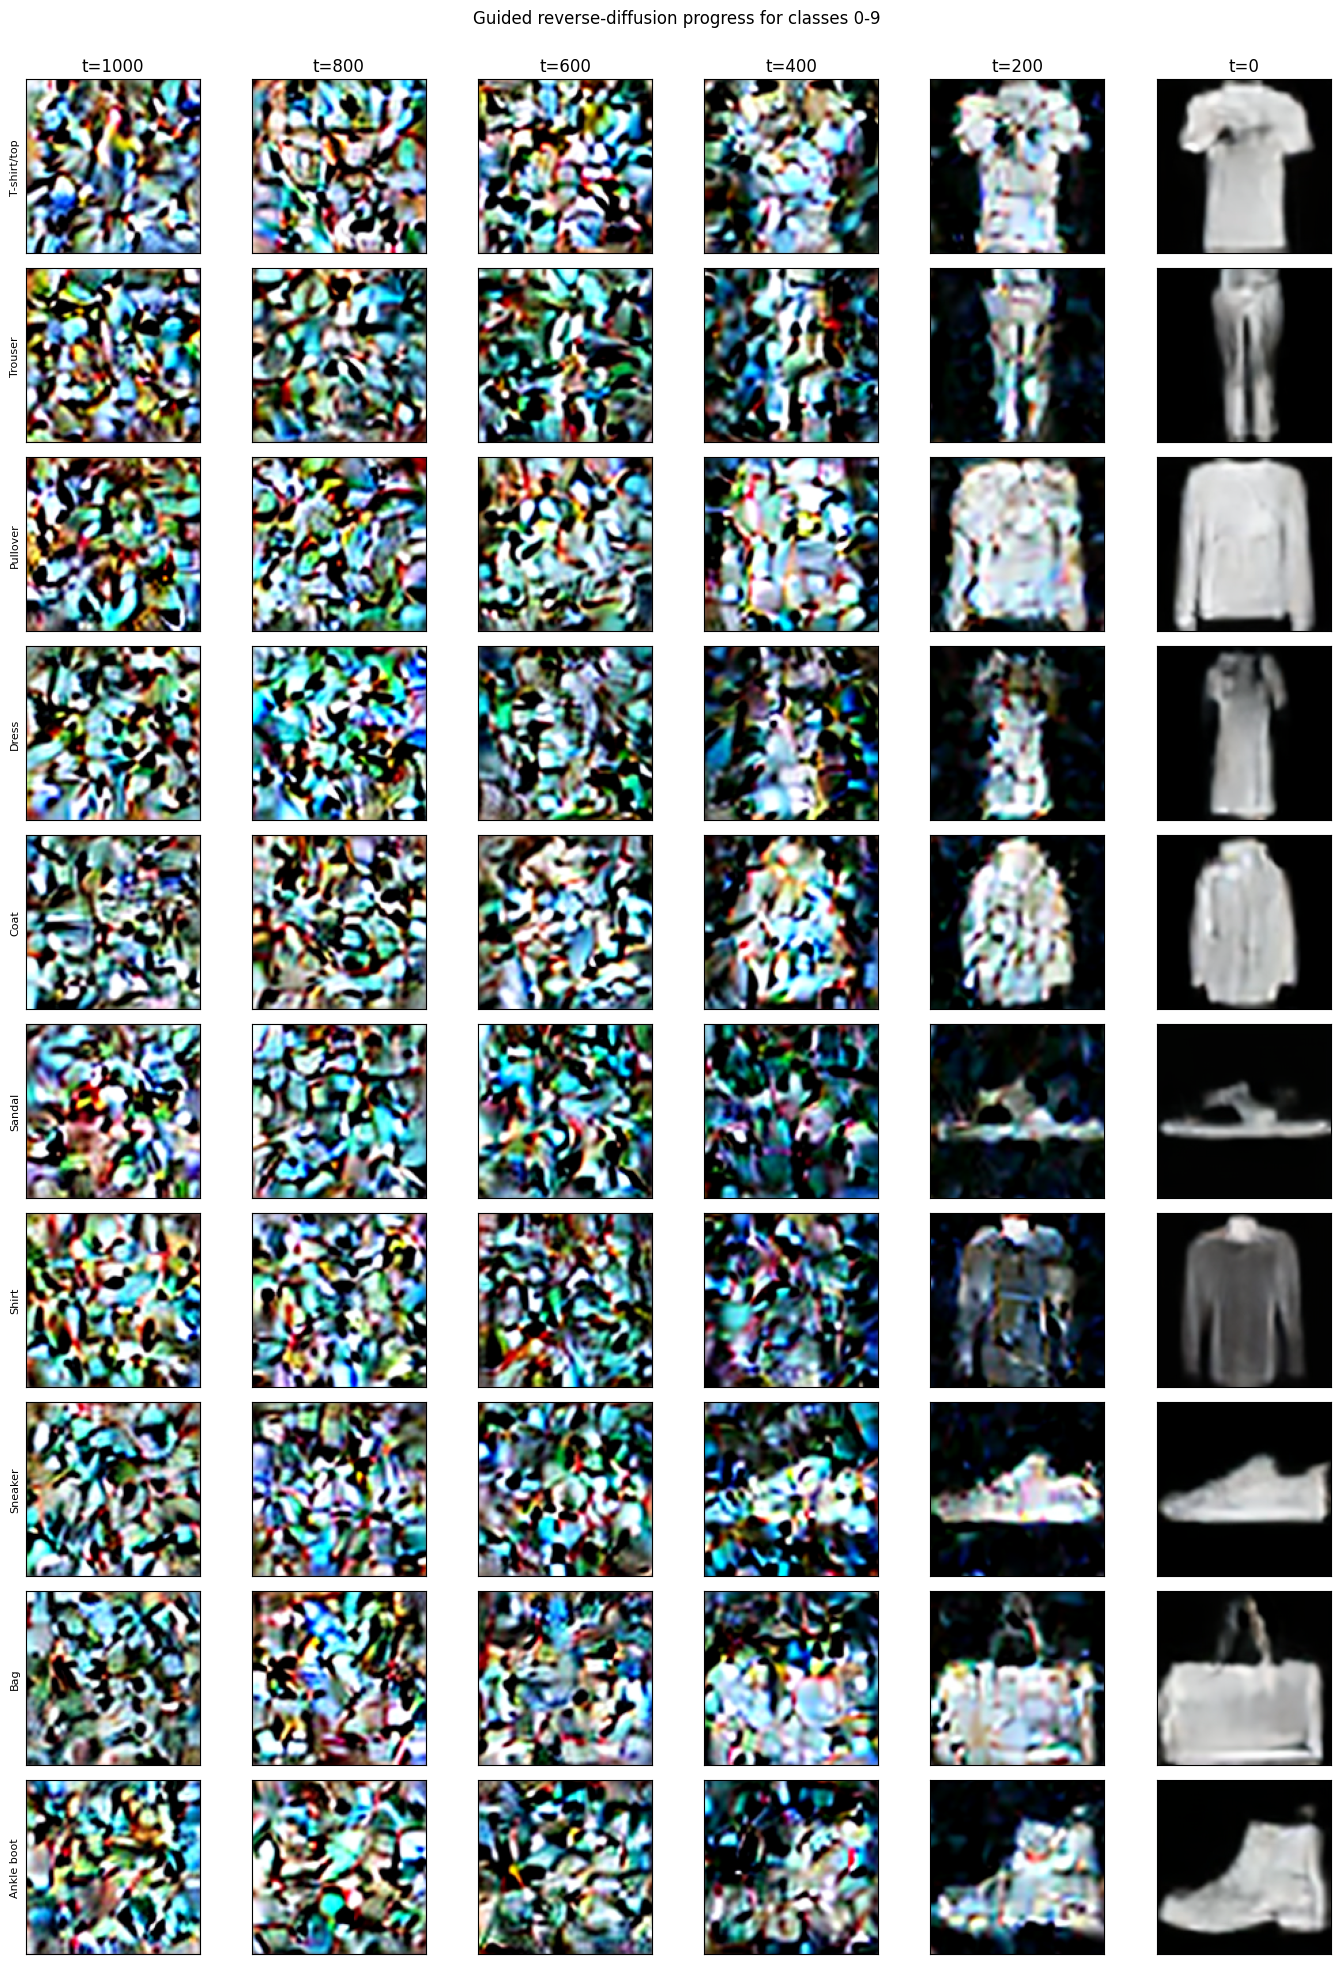

2026-11-04T00:10:52.589494+00:00 | Generated 64 conditional samples with w=3.0 in 35.48s
CFG diagnostics: {'conditional_prediction_rms': 0.9975590705871582, 'unconditional_prediction_rms': 0.9952810406684875, 'guided_prediction_rms': 1.0061028003692627, 'guidance_scale': 3.0}
STEP 10: PASS


In [10]:
@torch.inference_mode()
def sample_with_cfg(
    model: nn.Module,
    labels: torch.Tensor,
    guidance_scale: float = 3.0,
    seed: int = SEED,
):
    model.eval()
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    sample_count = len(labels)
    x = torch.randn(
        sample_count, LATENT_CHANNELS, 16, 16,
        device=DEVICE, generator=generator, dtype=torch.float32,
    )
    labels = labels.to(DEVICE)
    null_labels = torch.full_like(labels, NULL_LABEL)

    saved_latents = {1000: x[:10].detach().cpu()}
    cfg_diagnostics = {}
    snapshot_indices = {799: 800, 599: 600, 399: 400, 199: 200, 0: 0}

    for timestep in tqdm(range(NUM_DIFFUSION_STEPS - 1, -1, -1), desc="CFG sampling"):
        t = torch.full((sample_count,), timestep, device=DEVICE, dtype=torch.long)

        model_input = torch.cat([x, x], dim=0)
        timestep_input = torch.cat([t, t], dim=0)
        label_input = torch.cat([labels, null_labels], dim=0)

        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            combined_prediction = model(model_input, timestep_input, label_input)
        epsilon_conditional, epsilon_unconditional = combined_prediction.chunk(2, dim=0)
        predicted_noise = (
            (1.0 + guidance_scale) * epsilon_conditional
            - guidance_scale * epsilon_unconditional
        ).float()

        if timestep == NUM_DIFFUSION_STEPS - 1:
            cfg_diagnostics = {
                "conditional_prediction_rms": float(epsilon_conditional.float().square().mean().sqrt()),
                "unconditional_prediction_rms": float(epsilon_unconditional.float().square().mean().sqrt()),
                "guided_prediction_rms": float(predicted_noise.square().mean().sqrt()),
                "guidance_scale": guidance_scale,
            }

        alpha_t = extract(alphas, t, x.shape)
        alpha_bar_t = extract(alpha_bars, t, x.shape)
        alpha_bar_previous = extract(alpha_bars_prev, t, x.shape)
        beta_t = extract(betas, t, x.shape)

        mean = (1.0 / torch.sqrt(alpha_t)) * (
            x - beta_t / torch.sqrt(1.0 - alpha_bar_t) * predicted_noise
        )

        if timestep > 0:
            posterior_variance = beta_t * (1.0 - alpha_bar_previous) / (1.0 - alpha_bar_t)
            random_noise = torch.randn(x.shape, device=DEVICE, generator=generator)
            x = mean + torch.sqrt(posterior_variance.clamp(min=1e-20)) * random_noise
        else:
            x = mean

        if timestep in snapshot_indices:
            saved_latents[snapshot_indices[timestep]] = x[:10].detach().cpu()

    return x.detach().cpu(), saved_latents, cfg_diagnostics


target_labels = torch.tensor([index % NUM_CLASSES for index in range(NUM_SAMPLES)], dtype=torch.long)
sampling_start = time.perf_counter()
generated_latents, sampling_snapshots, cfg_diagnostics = sample_with_cfg(
    model, target_labels, guidance_scale=GUIDANCE_SCALE, seed=SEED
)
sampling_seconds = time.perf_counter() - sampling_start
generated_images = decode_latents(generated_latents, batch_size=16)

fig, axes = plt.subplots(8, 8, figsize=(12, 12))
for index, ax in enumerate(axes.flat):
    ax.imshow(((generated_images[index] + 1) / 2).permute(1, 2, 0).numpy())
    ax.set_title(f"{int(target_labels[index])}: {class_names[int(target_labels[index])]}", fontsize=7)
    ax.axis("off")
plt.suptitle("64 conditional Fashion-MNIST samples - CFG guidance scale w=3", fontsize=15)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(FIGURE_DIR / "conditional_samples_w3.png", dpi=200, bbox_inches="tight")
plt.show()

snapshot_order = [1000, 800, 600, 400, 200, 0]
decoded_snapshots = {
    timestep: decode_latents(sampling_snapshots[timestep])
    for timestep in snapshot_order
}
fig, axes = plt.subplots(10, len(snapshot_order), figsize=(14, 20))
for row in range(10):
    for column, timestep in enumerate(snapshot_order):
        axes[row, column].imshow(
            ((decoded_snapshots[timestep][row] + 1) / 2).permute(1, 2, 0).numpy()
        )
        if row == 0:
            axes[row, column].set_title(f"t={timestep}")
        if column == 0:
            axes[row, column].set_ylabel(class_names[row], fontsize=8)
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
plt.suptitle("Guided reverse-diffusion progress for classes 0-9")
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.savefig(FIGURE_DIR / "sampling_progress.png", dpi=180, bbox_inches="tight")
plt.show()

(OUTPUT_DIR / "cfg_diagnostics.json").write_text(
    json.dumps(cfg_diagnostics, indent=2), encoding="utf-8"
)
pd.DataFrame({
    "sample_index": np.arange(NUM_SAMPLES),
    "class_id": target_labels.numpy(),
    "class_name": [class_names[int(label)] for label in target_labels],
    "guidance_scale": GUIDANCE_SCALE,
}).to_csv(OUTPUT_DIR / "generated_sample_labels.csv", index=False)

log(f"Generated {NUM_SAMPLES} conditional samples with w={GUIDANCE_SCALE} in {sampling_seconds:.2f}s")
print("CFG diagnostics:", cfg_diagnostics)
print("STEP 10: PASS")


## 11. Generate final Step 0 submission artifacts

This cell creates the Markdown documentation, raw metrics, reproducibility
files, environment record, run log, and manifest. Values are taken from this
completed run rather than hard-coded.


In [11]:
final_train_loss = float(history_df.iloc[-1]["train_noise_mse"])
final_validation_loss = float(history_df.iloc[-1]["validation_noise_mse"])
best_validation_loss = float(best_validation_row["validation_noise_mse"])
best_validation_epoch = int(best_validation_row["epoch"])
mean_label_drop_fraction = float(history_df["observed_label_drop_fraction"].mean())

metrics = {
    "vae_reconstruction_mse": reconstruction_mse,
    "final_train_noise_mse": final_train_loss,
    "final_validation_noise_mse": final_validation_loss,
    "best_validation_noise_mse": best_validation_loss,
    "best_validation_epoch": best_validation_epoch,
    "mean_observed_label_drop_fraction": mean_label_drop_fraction,
    "conditional_sample_count": NUM_SAMPLES,
    "guidance_scale": GUIDANCE_SCALE,
    "diffusion_timesteps": NUM_DIFFUSION_STEPS,
    "model_parameters": total_parameters,
    "saved_model_size_mib": model_size_mib,
    "latent_cache_seconds": cache_seconds,
    "training_seconds_this_session": training_seconds_this_session,
    "sampling_seconds": sampling_seconds,
}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

run_config = {
    "student": STUDENT,
    "SID4": SID4,
    "SEED": SEED,
    "SLICE": SLICE,
    "HP_ID": HP_ID,
    "dataset": DATASET_NAME,
    "vae_model": VAE_MODEL,
    "image_size": IMAGE_SIZE,
    "latent_shape": [LATENT_CHANNELS, 16, 16],
    "latent_scale": LATENT_SCALE,
    "diffusion_timesteps": NUM_DIFFUSION_STEPS,
    "beta_schedule": "linear",
    "beta_start": BETA_START,
    "beta_end": BETA_END,
    "base_channels": BASE_CHANNELS,
    "channel_multipliers": list(CHANNEL_MULTIPLIERS),
    "epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "label_drop_probability": LABEL_DROP_PROBABILITY,
    "guidance_scale": GUIDANCE_SCALE,
    "train_examples": len(train_latents),
    "test_examples": len(test_latents),
    "fast_debug": FAST_DEBUG,
}
(OUTPUT_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")

environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "diffusers": diffusers.__version__,
    "transformers": transformers.__version__,
    "accelerate": accelerate.__version__,
    "safetensors": safetensors.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu": gpu_name,
    "gpu_memory_gib": gpu_memory_gib,
}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")

metrics_md = f'''# Homework 9 Metrics

Student: {STUDENT}
SID4: {SID4}
Seed: {SEED}

## Required configuration

| Item | Value |
|---|---:|
| Dataset | {DATASET_NAME} |
| Pretrained VAE | `{VAE_MODEL}` |
| Image / latent size | `{IMAGE_SIZE}x{IMAGE_SIZE}` / `4x16x16` |
| Latent scaling factor | {LATENT_SCALE} |
| Diffusion timesteps | {NUM_DIFFUSION_STEPS} |
| Linear beta range | [{BETA_START}, {BETA_END}] |
| U-Net base channels | {BASE_CHANNELS} |
| Channel multipliers | {CHANNEL_MULTIPLIERS} |
| Epochs | {NUM_EPOCHS} |
| Learning rate | {LEARNING_RATE} |
| Label drop probability | {LABEL_DROP_PROBABILITY} |
| Guidance scale | {GUIDANCE_SCALE} |
| Conditional samples | {NUM_SAMPLES} |

## Results

| Metric | Value |
|---|---:|
| VAE reconstruction MSE | {reconstruction_mse:.8f} |
| Final training noise MSE | {final_train_loss:.8f} |
| Final validation noise MSE | {final_validation_loss:.8f} |
| Best validation noise MSE | {best_validation_loss:.8f} |
| Best validation epoch | {best_validation_epoch} |
| Mean observed label-drop fraction | {mean_label_drop_fraction:.4f} |
| Trainable U-Net parameters | {trainable_parameters:,} |
| Saved U-Net size | {model_size_mib:.2f} MiB |
| Latent caching time | {cache_seconds:.2f} s |
| Sampling time | {sampling_seconds:.2f} s |
'''
(OUTPUT_DIR / "METRICS.md").write_text(metrics_md, encoding="utf-8")

analysis_md = f'''# Homework 9 Analysis

## VAE compression

The pretrained VAE compressed each 128x128, three-channel Fashion-MNIST image to a
4x16x16 latent tensor. The scaling factor was {LATENT_SCALE}. On the held-out
reconstruction batch, the normalized-pixel MSE was **{reconstruction_mse:.8f}**.
The side-by-side reconstruction figure shows the information retained by the frozen
VAE before diffusion training.

## Forward diffusion

The decoded latent sequence at t = 0, 200, 500, 800, and 1000 demonstrates the
progressive loss of recognizable clothing structure under the linear beta schedule.
At late timesteps, the decoded representation is dominated by Gaussian noise, as
expected from the decreasing cumulative alpha product.

## Denoising training

The conditional latent U-Net completed **{NUM_EPOCHS} epochs** at learning rate
**{LEARNING_RATE}**. Training noise MSE ended at **{final_train_loss:.8f}** and
held-out noise MSE ended at **{final_validation_loss:.8f}**. The best held-out MSE
was **{best_validation_loss:.8f}** at epoch **{best_validation_epoch}**. The mean
observed null-label fraction was **{mean_label_drop_fraction:.4f}**, close to the
required 0.10 probability.

## Classifier-free guidance

At every reverse step, conditional and null-label predictions were evaluated and
combined as `(1 + w) * epsilon_cond - w * epsilon_uncond` with `w = 3`. The final
8x8 figure contains 64 generated samples with Fashion-MNIST labels 0-9 repeated.
The sampling-progress figure shows how class-conditioned structure emerges from
noise. Differences between individual samples reflect the random initial latent and
the stochastic DDPM reverse process.

## Limitations

Fashion-MNIST was converted from grayscale to three channels solely for compatibility
with the pretrained RGB VAE. The VAE was trained on natural images rather than
Fashion-MNIST, so its reconstruction error places an upper bound on downstream image
fidelity. A longer or larger denoiser could improve samples but would change the
required architecture or training budget.
'''
(OUTPUT_DIR / "ANALYSIS.md").write_text(analysis_md, encoding="utf-8")

ai_use_md = '''# AI Use - Homework 9

I used an AI assistant to develop a first-cut notebook structure from the assignment
and the two instructor demos, explain latent diffusion and classifier-free guidance,
and help debug tensor shapes and artifact export. I reviewed the architecture, ran
every cell, checked the displayed outputs, and used the measured results from my own
run in the final analysis.

One important correction was image size. An early draft followed the demo and resized
Fashion-MNIST to 64x64. The Stable Diffusion VAE downsamples by a factor of eight, so
that produced 8x8 latents and could not satisfy the assignment requirement for
self-attention at 16x16. I changed preprocessing to 128x128, verified the encoded
shape was 4x16x16, and added an assertion before training. I also replaced the demo's
simple linear noise interpolation with the required alpha-bar Gaussian diffusion
equation and verified schedule indices for assignment timestep 1000.
'''
(OUTPUT_DIR / "AI_USE.md").write_text(ai_use_md, encoding="utf-8")

readme_md = f'''# DATA 266 Homework 9 - Conditional Latent Diffusion

Student: {STUDENT}
SID4: {SID4}

This submission implements a conditional latent diffusion model on Fashion-MNIST
using the frozen `{VAE_MODEL}` VAE and a custom latent U-Net trained for 50 epochs.

## Main files

- `HW9_Latent_Diffusion_Nikhil_Kanaparthi_6441.ipynb`: executed Colab notebook
- `METRICS.md`: required configuration and numerical results
- `ANALYSIS.md`: interpretation and limitations
- `RUN_LOG.txt`: timestamped execution record
- `AI_USE.md`: AI-use disclosure and corrected first-draft issue
- `training_history.csv`: epoch-level training and validation loss
- `metrics.json`, `run_config.json`, `environment.json`: machine-readable evidence
- `figures/`: reconstruction, forward diffusion, loss, and sampling figures
- `models/conditional_latent_unet_fp16.safetensors`: trained denoiser weights
- `models/vae_reference.json`: exact pretrained VAE reference

## Reproduction

Open the notebook in Colab, choose a GPU runtime, keep `FAST_DEBUG = False`, and run
all cells in order. The final cell creates `HW9_outputs.zip`.

## Repository submission

Place the executed notebook and extracted output files in the `HW9/` folder of the
course repository. Commit progressively, push `main`, create annotated tag `hw9`,
create the GitHub release, and submit the release URL in Canvas.
'''
(OUTPUT_DIR / "README.md").write_text(readme_md, encoding="utf-8")

log(f"Final metrics: {json.dumps(metrics, sort_keys=True)}")
(OUTPUT_DIR / "RUN_LOG.txt").write_text("\n".join(RUN_LOG_LINES) + "\n", encoding="utf-8")

print("Created submission artifacts:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(" -", path.relative_to(OUTPUT_DIR))
print("STEP 11: PASS")


2026-11-04T00:10:52.618337+00:00 | Final metrics: {"best_validation_epoch": 48, "best_validation_noise_mse": 0.0994340169429779, "conditional_sample_count": 64, "diffusion_timesteps": 1000, "final_train_noise_mse": 0.10047931772470474, "final_validation_noise_mse": 0.10219185214042664, "guidance_scale": 3.0, "latent_cache_seconds": 463.716676652, "mean_observed_label_drop_fraction": 0.09977233333333334, "model_parameters": 11717636, "sampling_seconds": 35.481023151000045, "saved_model_size_mib": 22.369583129882812, "training_seconds_this_session": 2468.511736597, "vae_reconstruction_mse": 0.0006073939148336649}
Created submission artifacts:
 - AI_USE.md
 - ANALYSIS.md
 - METRICS.md
 - README.md
 - RUN_LOG.txt
 - cfg_diagnostics.json
 - environment.json
 - figures/conditional_samples_w3.png
 - figures/forward_diffusion_decodes.png
 - figures/sampling_progress.png
 - figures/training_loss.png
 - figures/vae_reconstruction.png
 - generated_sample_labels.csv
 - metrics.json
 - models/condi

## 12. Validate and export the submission ZIP

The ZIP intentionally excludes the temporary optimizer checkpoint and downloaded
Fashion-MNIST files. Download both the ZIP and the executed notebook from Colab.


In [12]:
# Build a final manifest after all artifacts exist.
manifest_lines = []
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file() and path.name != "submission_manifest.txt":
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        manifest_lines.append(f"{digest}  {path.relative_to(OUTPUT_DIR)}")
(OUTPUT_DIR / "submission_manifest.txt").write_text(
    "\n".join(manifest_lines) + "\n", encoding="utf-8"
)

required_paths = [
    OUTPUT_DIR / "METRICS.md",
    OUTPUT_DIR / "ANALYSIS.md",
    OUTPUT_DIR / "AI_USE.md",
    OUTPUT_DIR / "README.md",
    OUTPUT_DIR / "RUN_LOG.txt",
    OUTPUT_DIR / "training_history.csv",
    OUTPUT_DIR / "metrics.json",
    FIGURE_DIR / "vae_reconstruction.png",
    FIGURE_DIR / "forward_diffusion_decodes.png",
    FIGURE_DIR / "training_loss.png",
    FIGURE_DIR / "conditional_samples_w3.png",
    FIGURE_DIR / "sampling_progress.png",
    MODEL_DIR / "conditional_latent_unet_fp16.safetensors",
]
missing = [str(path) for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(f"Missing required submission files: {missing}")

assert len(history_df) == NUM_EPOCHS
assert NUM_SAMPLES == 64
assert not FAST_DEBUG, "Set FAST_DEBUG=False and rerun before final submission."

zip_base = Path("/content/HW9_outputs") if Path("/content").exists() else Path.cwd() / "HW9_outputs"
zip_path = Path(shutil.make_archive(str(zip_base), "zip", root_dir=OUTPUT_DIR))
print(f"Created: {zip_path} ({zip_path.stat().st_size / 1024**2:.2f} MiB)")
print("FINAL VALIDATION: PASS")

try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Not running in Colab; ZIP is available at", zip_path)


Created: /content/HW9_outputs.zip (31.86 MiB)
FINAL VALIDATION: PASS


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>